# LAB013–015: temperatura, CO₂ RAW y química

Temperatura y flujo de CO₂ RAW con **medias aritméticas en intervalos de 30 minutos**, en dos figuras separadas de 1×3 paneles: una de CO₂ RAW y otra de temperatura, con un panel por fermentador. Se usan los archivos originales `Temp_F*_LAB0*.csv` y `CO2_F*_LAB0*_SF.csv` de `data/original/natural/lab013_015`.

Las ventanas son comunes a ambas señales: [hh:00, hh:30) y [hh:30, hh+1:00), representadas en su centro. Cada media usa las lecturas disponibles, incluidos ceros y estados de bajo/alto rango. Las ventanas sin observaciones quedan como huecos. No se aplica filtrado, corrección, interpolación ni conversión del flujo RAW (sccm).

La química se muestra en sus tiempos originales, sin promediar: analizador Y15 y planilla de mediciones offline. Todos los ejes usan fecha y hora registradas; no se presupone un instante de inoculación. Las figuras y tablas quedan dentro del EXECUTED.

### Registro de nutrición

Los archivos de temperatura incluyen `nutricion_activa` (estado de la bomba comandado por la GUI) y `freq_nut` (frecuencia configurada en Hz). En LAB013–015 todas las filas tienen `nutricion_activa = 0` y `freq_nut = 1000`. No hay activaciones registradas que marcar. Esto no permite descartar adiciones manuales ni activaciones entre lecturas o fuera de la cobertura. La frecuencia configurada por sí sola no indica bombeo.


In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/wine_fermentation').is_dir() and (p / 'data/sources.csv').is_file())
DATA = ROOT / 'data/original/natural/lab013_015'
LABS = (('F1', 'LAB013'), ('F2', 'LAB014'), ('F3', 'LAB015'))
COLORS = {'LAB013': '#0072B2', 'LAB014': '#D55E00', 'LAB015': '#009E73'}
plt.rcParams.update({'figure.dpi': 120, 'font.family': 'DejaVu Sans', 'font.size': 10})

def date_axis(ax):
    locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m\n%H:%M'))
    ax.set_xlabel('Fecha y hora registradas (2026)')
    ax.grid(alpha=0.25)

RAW, TEMP, MEANS = {}, {}, {}
coverage = []
for fermenter, lab in LABS:
    RAW[lab] = pd.read_csv(DATA / f'CO2_{fermenter}_{lab}_SF.csv', parse_dates=['timestamp']).sort_values('timestamp')
    TEMP[lab] = pd.read_csv(DATA / f'Temp_{fermenter}_{lab}.csv', parse_dates=['timestamp']).sort_values('timestamp')
    series = []
    for family, frame, column in [('CO₂ RAW', RAW[lab], 'flow_sccm'), ('Temperatura', TEMP[lab], 'T')]:
        values = frame.set_index('timestamp')[column]
        grouped = values.resample('30min', origin='start_day', closed='left', label='left')
        means = grouped.mean()
        means.index += pd.Timedelta(minutes=15)
        series.append(means)
        coverage.append({'lab': lab, 'señal': family, 'inicio': frame.timestamp.min(),
                         'fin': frame.timestamp.max(), 'lecturas': int(values.count()),
                         'ventanas con datos': int(means.notna().sum()),
                         'ventanas vacías': int(means.isna().sum())})
    MEANS[lab] = pd.concat(series, axis=1)
display(pd.DataFrame(coverage))

nutrition_summary = []
for fermenter, lab in LABS:
    frame = TEMP[lab]
    active = frame['nutricion_activa'].eq(1)
    nutrition_summary.append({
        'lab': lab,
        'lecturas de estado': int(frame['nutricion_activa'].notna().sum()),
        'lecturas activas': int(active.sum()),
        'inicios de activación registrados': int((active & ~active.shift(fill_value=False)).sum()),
        'frecuencia configurada [Hz]': ', '.join(map(str, sorted(frame['freq_nut'].dropna().unique()))),
    })
display(pd.DataFrame(nutrition_summary))


,lab,señal,inicio,fin,lecturas,ventanas con datos,ventanas vacías
0,LAB013,CO₂ RAW,2026-08-18 11:21:39,2026-08-26 10:00:37,65590,383,0
1,LAB013,Temperatura,2026-08-18 11:20:36,2026-08-26 10:00:35,193049,383,0
2,LAB014,CO₂ RAW,2026-08-18 11:21:49,2026-08-26 10:00:37,65589,383,0
3,LAB014,Temperatura,2026-08-18 11:20:50,2026-08-26 10:00:40,193046,383,0
4,LAB015,CO₂ RAW,2026-08-18 11:22:09,2026-08-26 10:00:37,65587,383,0
5,LAB015,Temperatura,2026-08-18 11:21:05,2026-08-26 10:00:44,193043,383,0


,lab,lecturas de estado,lecturas activas,inicios de activación registrados,frecuencia configurada [Hz]
0,LAB013,193049,0,0,1000.0
1,LAB014,193046,0,0,1000.0
2,LAB015,193043,0,0,1000.0


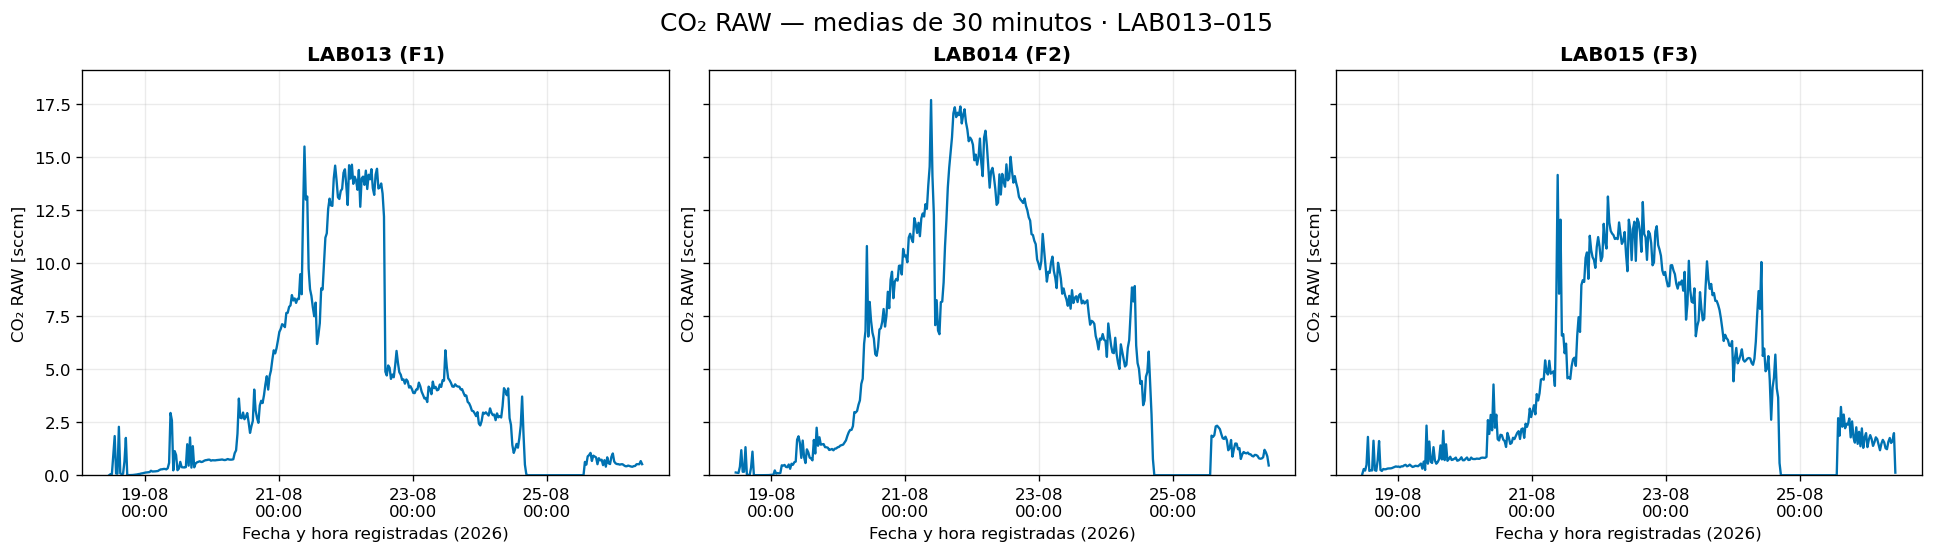

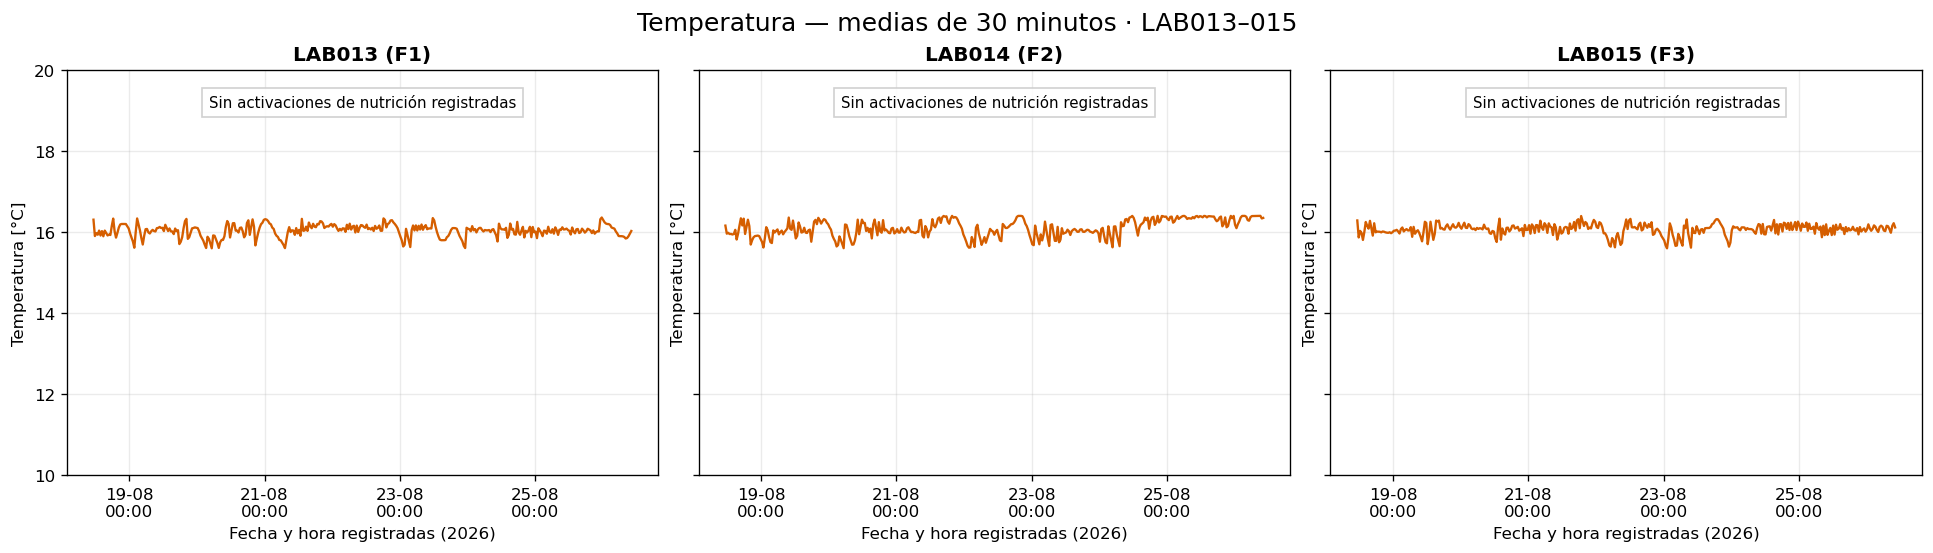

In [24]:
for column, title, ylabel, color in (
    ('flow_sccm', 'CO₂ RAW', 'CO₂ RAW [sccm]', '#0072B2'),
    ('T', 'Temperatura', 'Temperatura [°C]', '#D55E00'),
):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True,
                             layout='constrained')
    for ax, (fermenter, lab) in zip(axes, LABS):
        frame = MEANS[lab]
        ax.plot(frame.index, frame[column], color=color, lw=1.4)
        ax.set_title(f'{lab} ({fermenter})', fontweight='bold')
        ax.set_ylabel(ylabel)
        date_axis(ax)
        if column == 'flow_sccm':
            ax.set_ylim(0, max(d[column].max() for d in MEANS.values()) * 1.08)
        else:
            ax.set_ylim(10, 20)
            if not TEMP[lab]['nutricion_activa'].eq(1).any():
                ax.text(0.5, 0.94, 'Sin activaciones de nutrición registradas',
                        transform=ax.transAxes, ha='center', va='top', fontsize=9,
                        bbox={'facecolor': 'white', 'edgecolor': '0.8', 'alpha': 0.9})

    fig.suptitle(f'{title} — medias de 30 minutos · LAB013–015', fontsize=15)
    plt.show()


## CO₂ RAW sin promediar

Lecturas originales de `flow_sccm`, sin filtrado ni agregación temporal. Se conservan todos los estados del sensor y los ceros registrados. Los huecos sin lecturas se interrumpen cuando la separación supera un minuto.

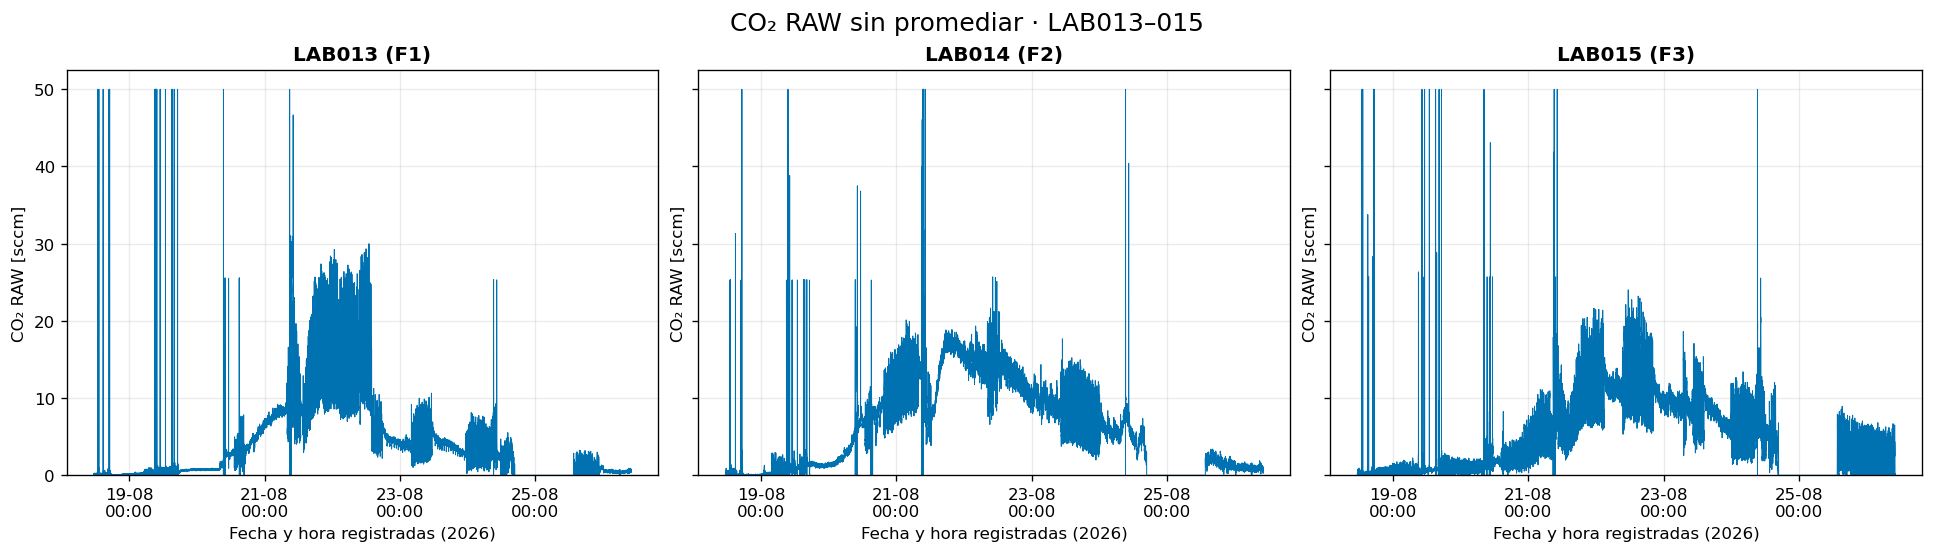

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True,
                         layout='constrained')
raw_max = max(frame.flow_sccm.max() for frame in RAW.values())
for ax, (fermenter, lab) in zip(axes, LABS):
    frame = RAW[lab]
    # Insert a missing point inside long gaps without discarding either endpoint.
    signal = frame.set_index('timestamp')['flow_sccm']
    gaps = signal.index.to_series().diff().gt(pd.Timedelta(minutes=1))
    breaks = signal.index[gaps.to_numpy()] - pd.Timedelta(microseconds=1)
    signal = signal.reindex(signal.index.union(breaks)).sort_index()
    ax.plot(signal.index, signal, color='#0072B2', lw=0.6)
    ax.set_title(f'{lab} ({fermenter})', fontweight='bold')
    ax.set_ylabel('CO₂ RAW [sccm]')
    ax.set_ylim(0, raw_max * 1.05)
    date_axis(ax)
fig.suptitle('CO₂ RAW sin promediar · LAB013–015', fontsize=15)
plt.show()


## LAB014: reconstrucción simulada de los tramos señalados

Escenario ilustrativo basado en el dibujo de referencia, **no mediciones recuperadas**. Las señales originales y sus figuras anteriores se conservan. Se generan lecturas sintéticas solo en memoria para LAB014, con pequeños residuos deterministas de media cero por ventana. Sus medias de 30 minutos siguen la tendencia de los puentes entre los puntos de control, con ruido correlacionado reproducible (semilla 14030, correlación AR(1) de 0,4). La dispersión relativa se estima con residuos respecto de una mediana móvil de cinco ventanas en las 24 h cercanas a cada extremo, excluyendo los puentes. Se limita entre 1,5 % y 6 % para este escenario ilustrativo. El ruido disminuye hasta cero en los puntos de control para conservar las uniones. No es una estimación de incertidumbre de las mediciones.

Primer puente: centros de ventana del 21-08 06:15 al 21-08 17:45, entre las medias originales de los extremos. Segundo puente: del 24-08 08:15 al 25-08 22:15, con un punto intermedio el 25-08 12:15 a 2,8 sccm. Las fechas son de 2026 y aproximan las líneas rojas del dibujo. La selección de tramos es manual, no una detección automática de averías.

En la figura, gris indica la media original de LAB014 y rojo los puentes simulados. LAB013 y LAB015 conservan sus medias originales. No se exportan ni sobrescriben archivos de datos.

,centro de ventana,punto de control [sccm]
0,2026-08-21 06:15:00,12.332134
1,2026-08-21 17:45:00,17.335379
2,2026-08-24 08:15:00,6.367861
3,2026-08-25 12:15:00,2.800000
4,2026-08-25 22:15:00,1.496328


,inicio del puente,dispersión relativa usada [%]
0,2026-08-21 06:15:00,2.520942
1,2026-08-24 08:15:00,3.916760


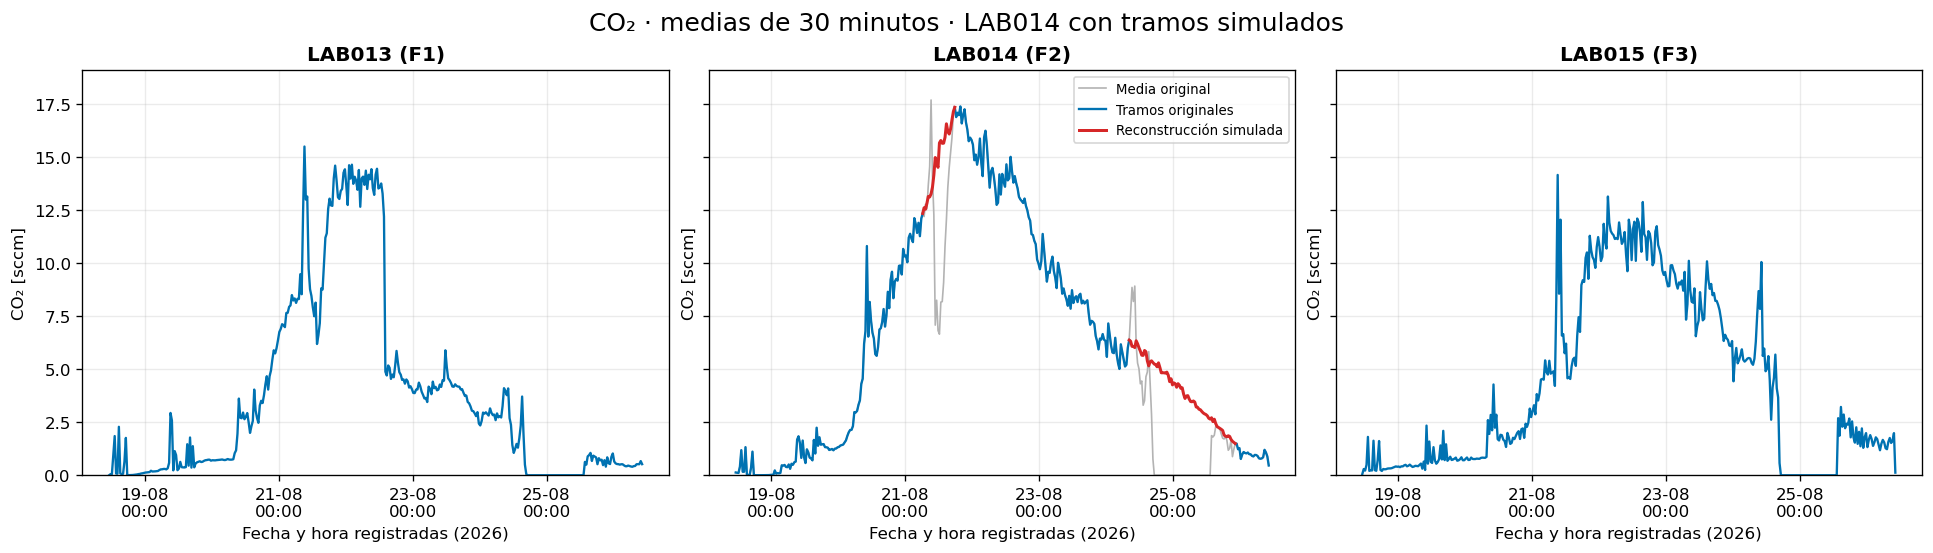

In [26]:
original_014 = MEANS['LAB014']['flow_sccm']
SIMULATED_RAW_014 = RAW['LAB014'][['timestamp', 'flow_sccm']].copy()
SIMULATED_RAW_014['simulado'] = False
target_014 = original_014.copy()
simulated_windows = pd.Series(False, index=original_014.index)
BRIDGES_014 = [
    [pd.Timestamp('2026-08-21 06:15'), pd.Timestamp('2026-08-21 17:45')],
    [pd.Timestamp('2026-08-24 08:15'), pd.Timestamp('2026-08-25 12:15'), pd.Timestamp('2026-08-25 22:15')],
]
# Reproducible fluctuations of the 30-minute means, independent of within-window noise.
rng_014 = np.random.default_rng(14030)
bridge_summary = []
noise_summary = []
for knots in BRIDGES_014:
    values = ([original_014.loc[knots[0]], original_014.loc[knots[-1]]]
              if len(knots) == 2 else [original_014.loc[knots[0]], 2.8, original_014.loc[knots[-1]]])
    mask = (target_014.index > knots[0]) & (target_014.index < knots[-1])
    relative_hours = lambda dates: (pd.DatetimeIndex(dates) - knots[0]).total_seconds() / 3600
    target_014.loc[mask] = np.interp(relative_hours(target_014.index[mask]), relative_hours(knots), values)
    # Estimate relative scatter from nearby measured windows outside both bridges.
    nearby = ((original_014.index >= knots[0] - pd.Timedelta(hours=24)) &
              (original_014.index <= knots[-1] + pd.Timedelta(hours=24)))
    for excluded in BRIDGES_014:
        nearby &= ~((original_014.index >= excluded[0]) & (original_014.index <= excluded[-1]))
    baseline = original_014.rolling(5, center=True, min_periods=3).median()
    relative_residual = ((original_014 - baseline) / baseline).loc[nearby]
    relative_residual = relative_residual.replace([np.inf, -np.inf], np.nan).dropna()
    relative_sigma = 1.4826 * (relative_residual - relative_residual.median()).abs().median()
    # Bounds keep this illustrative scenario moderately noisy even near sensor zeros.
    relative_sigma = float(np.clip(relative_sigma, 0.015, 0.06))
    dates = target_014.index[mask]
    hours = relative_hours(dates)
    knot_hours = relative_hours(knots)
    ar_noise = rng_014.normal(size=len(dates))
    for j in range(1, len(ar_noise)):
        ar_noise[j] = 0.4 * ar_noise[j-1] + np.sqrt(1 - 0.4**2) * ar_noise[j]
    # Smoothly taper noise to zero at each control point, preserving joins and trend.
    envelope = np.zeros(len(dates))
    for left, right in zip(knot_hours[:-1], knot_hours[1:]):
        segment = (hours >= left) & (hours <= right)
        envelope[segment] = np.sin(np.pi * (hours[segment] - left) / (right - left)) ** 0.5
    target_014.loc[mask] *= 1 + relative_sigma * np.clip(ar_noise, -2.5, 2.5) * envelope
    noise_summary.append({'inicio del puente': knots[0], 'dispersión relativa usada [%]': 100 * relative_sigma})
    simulated_windows.loc[mask] = True
    for stamp, value in zip(knots, values):
        bridge_summary.append({'centro de ventana': stamp, 'punto de control [sccm]': value})

raw_centers = SIMULATED_RAW_014.timestamp.dt.floor('30min') + pd.Timedelta(minutes=15)
for center in target_014.index[simulated_windows]:
    mask = raw_centers.eq(center)
    count = int(mask.sum())
    if count:
        residual = 0.08 * np.sin(np.arange(count) * 2 * np.pi / 17)
        residual -= residual.mean()
        SIMULATED_RAW_014.loc[mask, 'flow_sccm'] = target_014.loc[center] + residual
        SIMULATED_RAW_014.loc[mask, 'simulado'] = True

SIMULATED_MEAN_014 = SIMULATED_RAW_014.set_index('timestamp').flow_sccm.resample(
    '30min', origin='start_day', closed='left', label='left').mean()
SIMULATED_MEAN_014.index += pd.Timedelta(minutes=15)
assert np.allclose(SIMULATED_MEAN_014.loc[simulated_windows], target_014.loc[simulated_windows])
assert np.allclose(SIMULATED_MEAN_014.loc[~simulated_windows], original_014.loc[~simulated_windows], equal_nan=True)
assert (SIMULATED_RAW_014.flow_sccm >= 0).all()
display(pd.DataFrame(bridge_summary))
display(pd.DataFrame(noise_summary))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True, layout='constrained')
for ax, (fermenter, lab) in zip(axes, LABS):
    measured = MEANS[lab].flow_sccm
    if lab == 'LAB014':
        ax.plot(measured.index, measured, color='0.7', lw=1, label='Media original')
        acquired = SIMULATED_MEAN_014.mask(simulated_windows)
        ax.plot(acquired.index, acquired, color='#0072B2', lw=1.4, label='Tramos originales')
        for knots in BRIDGES_014:
            bridge = SIMULATED_MEAN_014.loc[knots[0]:knots[-1]]
            ax.plot(bridge.index, bridge, color='#D62728', lw=1.8,
                    label='Reconstrucción simulada' if knots == BRIDGES_014[0] else None)
        ax.legend(fontsize=8, loc='upper right')
    else:
        ax.plot(measured.index, measured, color='#0072B2', lw=1.4)
    ax.set_title(f'{lab} ({fermenter})', fontweight='bold')
    ax.set_ylabel('CO₂ [sccm]')
    ax.set_ylim(0, max(d.flow_sccm.max() for d in MEANS.values()) * 1.08)
    date_axis(ax)
fig.suptitle('CO₂ · medias de 30 minutos · LAB014 con tramos simulados', fontsize=15)
plt.show()


## LAB014: área bajo la curva de la serie completada

Integración trapezoidal de la serie completada de LAB014 (medias de 30 minutos con los puentes simulados de la sección anterior), entre el primer y el último centro de ventana con datos. LAB014 no tiene ventanas vacías: los tramos reemplazados eran lecturas registradas del sensor, no huecos.

El sombreado distingue los tramos medidos de los puentes simulados, con los puntos de control compartidos como fronteras. El área en sccm·h equivale a un volumen estándar: multiplicada por 60 min/h da centímetros cúbicos estándar, es decir, el CO₂ acumulado durante el registro [L]. El desglose separa los tramos medidos de los puentes y compara el área de cada puente con la de las medias originales en el mismo tramo. No es un balance de masa verificado: hereda el carácter ilustrativo de los puentes simulados.


,tramo,área [sccm·h],CO₂ equivalente [L]
0,serie completada,1250.927642,75.055659
1,tramos medidos (fuera de puentes),929.923899,55.795434
2,puentes simulados,321.003743,19.260225


,puente,área simulada [sccm·h],área de las medias originales en el mismo tramo [sccm·h]
0,21-08 06:15 → 21-08 17:45,170.894753,138.892755
1,24-08 08:15 → 25-08 22:15,150.108991,61.274007


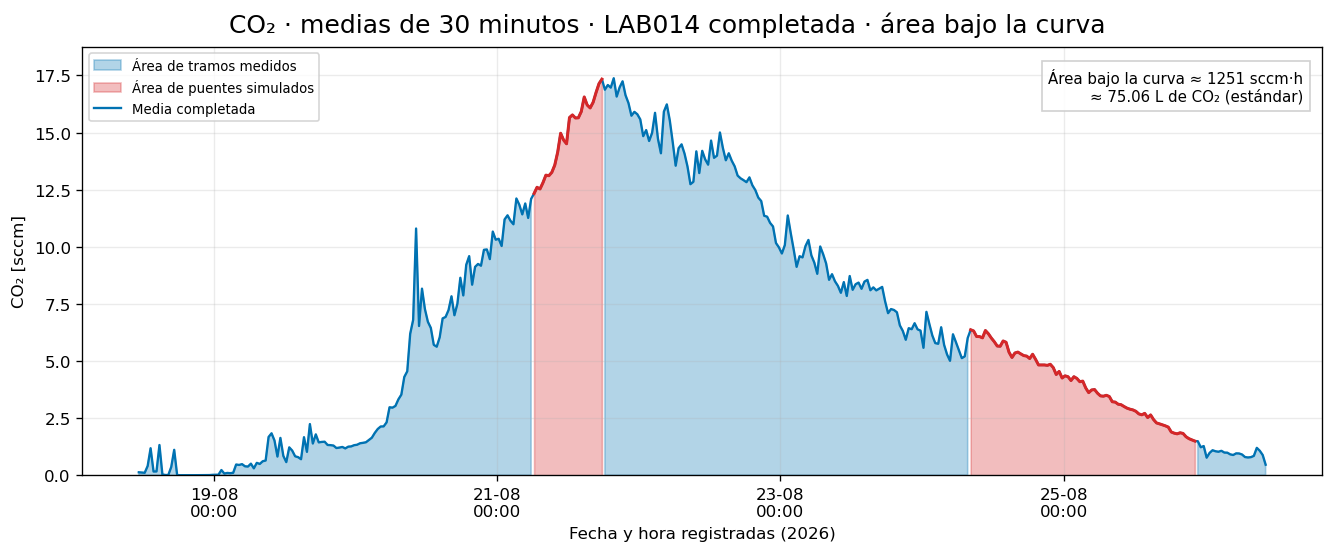

In [27]:
completed_014 = SIMULATED_MEAN_014.dropna()

def area_sccm_h(series):
    hours = (series.index - series.index[0]).total_seconds() / 3600
    return float(np.trapz(series.to_numpy(), hours))

auc_total = area_sccm_h(completed_014)
bridge_rows = []
simulated_mask = pd.Series(False, index=completed_014.index)
for knots in BRIDGES_014:
    simulated_mask.loc[knots[0]:knots[-1]] = True
    bridge_rows.append({
        'puente': f'{knots[0]:%d-%m %H:%M} → {knots[-1]:%d-%m %H:%M}',
        'área simulada [sccm·h]': area_sccm_h(SIMULATED_MEAN_014.loc[knots[0]:knots[-1]]),
        'área de las medias originales en el mismo tramo [sccm·h]': area_sccm_h(original_014.loc[knots[0]:knots[-1]]),
    })
auc_bridges = float(sum(row['área simulada [sccm·h]'] for row in bridge_rows))
summary = pd.DataFrame({'tramo': ['serie completada', 'tramos medidos (fuera de puentes)', 'puentes simulados'],
                        'área [sccm·h]': [auc_total, auc_total - auc_bridges, auc_bridges]})
summary['CO₂ equivalente [L]'] = summary['área [sccm·h]'] * 60 / 1000
display(summary)
display(pd.DataFrame(bridge_rows))

fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
ax.fill_between(completed_014.index, 0, completed_014, where=~simulated_mask.to_numpy(),
                color='#0072B2', alpha=0.30, label='Área de tramos medidos')
for knots in BRIDGES_014:
    span = SIMULATED_MEAN_014.loc[knots[0]:knots[-1]]
    ax.fill_between(span.index, 0, span, color='#D62728', alpha=0.30,
                    label='Área de puentes simulados' if knots == BRIDGES_014[0] else None)
ax.plot(completed_014.index, completed_014, color='#0072B2', lw=1.4, label='Media completada')
for knots in BRIDGES_014:
    span = SIMULATED_MEAN_014.loc[knots[0]:knots[-1]]
    ax.plot(span.index, span, color='#D62728', lw=1.8)
ax.text(0.985, 0.95, f'Área bajo la curva ≈ {auc_total:.0f} sccm·h\n'
        f'≈ {auc_total * 60 / 1000:.2f} L de CO₂ (estándar)',
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox={'facecolor': 'white', 'edgecolor': '0.8', 'alpha': 0.9})
ax.set_ylabel('CO₂ [sccm]')
ax.set_ylim(0, completed_014.max() * 1.08)
ax.legend(fontsize=8, loc='upper left')
date_axis(ax)
fig.suptitle('CO₂ · medias de 30 minutos · LAB014 completada · área bajo la curva', fontsize=15)
plt.show()

## Química del analizador Y15

Fuente: `Y15_LAB013-015.csv`. Se conservan los siete analitos y las ocho muestras de cada laboratorio, incluida la muestra pre-inóculo. El eje temporal corresponde a `y15_datetime` (hora del análisis Y15), que difiere de la hora de muestreo de la planilla offline. Los puntos son mediciones; las líneas solo permiten seguir cada serie.

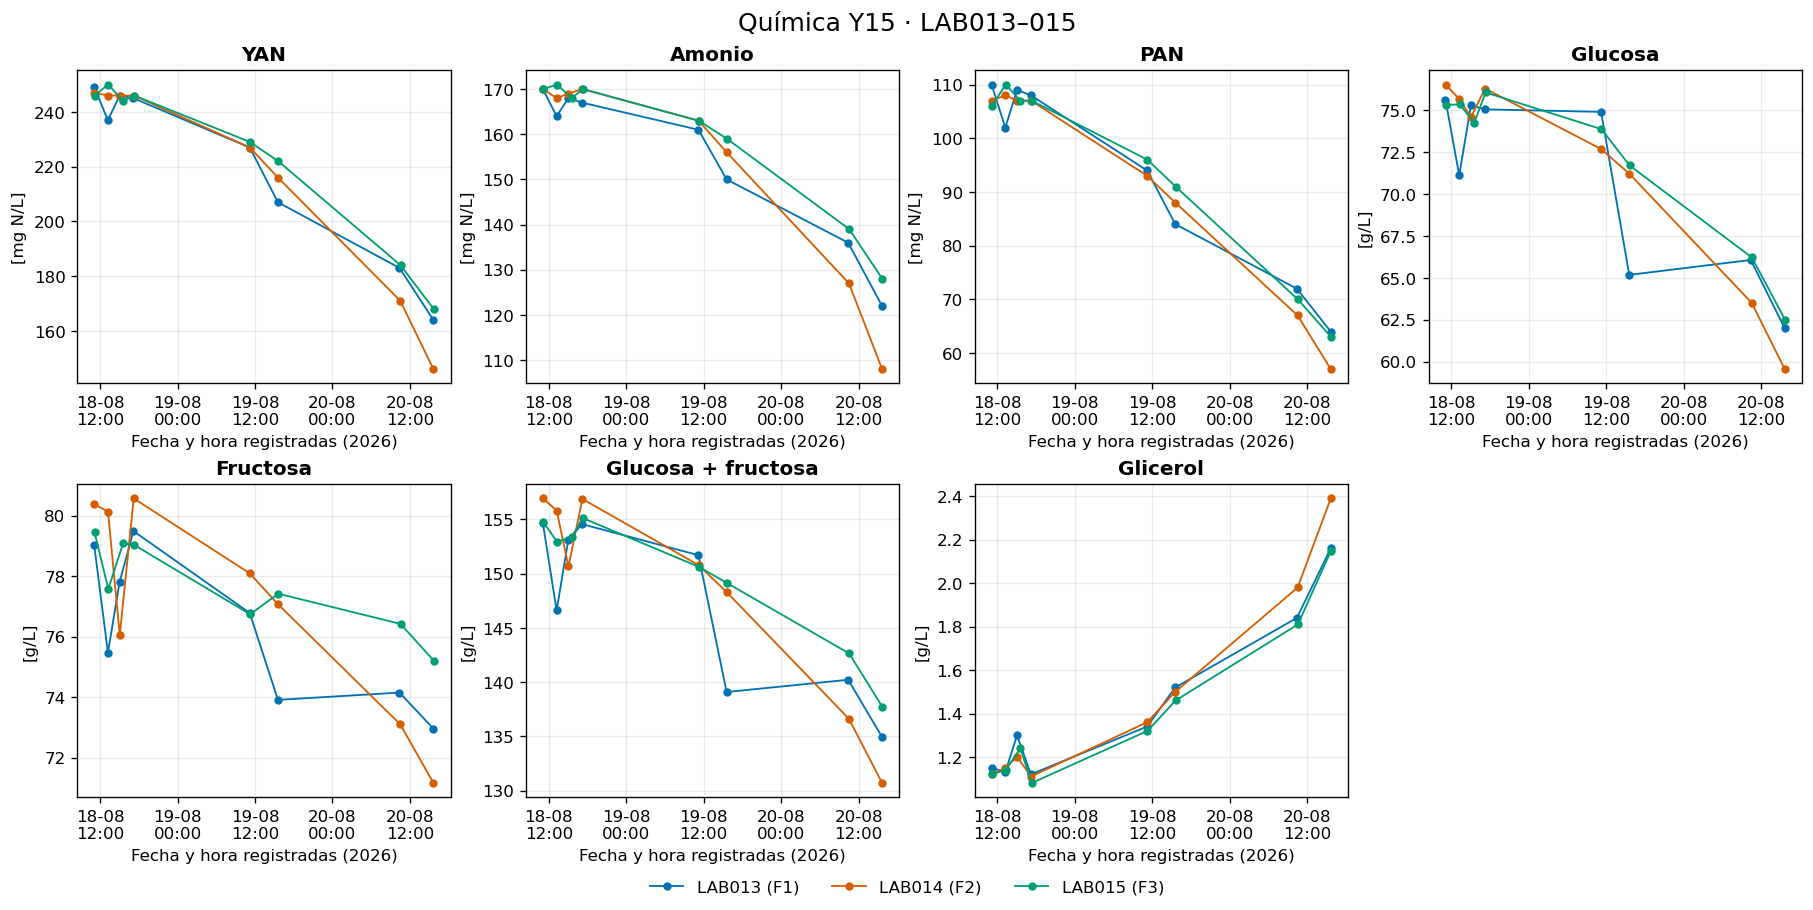

,sample_id,lab_id,sample_type,y15_datetime,YAN_mg_L,ammonia_mg_L,PAN_mg_L,glucose_g_L,fructose_g_L,glucose_fructose_g_L,glycerol_g_L
0,LAB013-PI,LAB013,pre_inoculum,2026-08-18 11:05:18,249.0,170.0,110.0,75.62,79.03,154.65,1.15
1,LAB013-2,LAB013,fermentation_sample,2026-08-18 13:12:58,237.0,164.0,102.0,71.13,75.47,146.60,1.13
2,LAB013-3,LAB013,fermentation_sample,2026-08-18 15:02:13,246.0,168.0,109.0,75.31,77.82,153.13,1.30
3,LAB013-4,LAB013,fermentation_sample,2026-08-18 17:10:13,245.0,167.0,108.0,75.06,79.49,154.55,1.12
4,LAB013-5,LAB013,fermentation_sample,2026-08-19 11:11:09,227.0,161.0,94.0,74.91,76.78,151.69,1.34
5,LAB013-6,LAB013,fermentation_sample,2026-08-19 15:32:51,207.0,150.0,84.0,65.18,73.91,139.09,1.52
6,LAB013-7,LAB013,fermentation_sample,2026-08-20 10:22:27,183.0,136.0,72.0,66.07,74.15,140.22,1.84
7,LAB013-8,LAB013,fermentation_sample,2026-08-20 15:37:23,164.0,122.0,64.0,61.99,72.96,134.95,2.16
8,LAB014-PI,LAB014,pre_inoculum,2026-08-18 11:06:06,247.0,170.0,107.0,76.54,80.38,156.92,1.12
9,LAB014-2,LAB014,fermentation_sample,2026-08-18 13:13:46,246.0,168.0,108.0,75.67,80.13,155.80,1.15


In [28]:
Y15 = pd.read_csv(DATA / 'Y15_LAB013-015.csv', parse_dates=['y15_datetime'])
Y15 = Y15.sort_values(['lab_id', 'y15_datetime'])
ANALYTES = (
    ('YAN_mg_L', 'YAN', 'mg N/L'),
    ('ammonia_mg_L', 'Amonio', 'mg N/L'),
    ('PAN_mg_L', 'PAN', 'mg N/L'),
    ('glucose_g_L', 'Glucosa', 'g/L'),
    ('fructose_g_L', 'Fructosa', 'g/L'),
    ('glucose_fructose_g_L', 'Glucosa + fructosa', 'g/L'),
    ('glycerol_g_L', 'Glicerol', 'g/L'),
)

def plot_chemistry(frame, time_column, variables, title, shape):
    fig, axes = plt.subplots(*shape, figsize=(15, 7.5), layout='constrained')
    for ax, (column, label, unit) in zip(axes.flat, variables):
        for fermenter, lab in LABS:
            sample = frame.loc[frame.lab_id.eq(lab)].sort_values(time_column)
            ax.plot(sample[time_column], sample[column], marker='o', ms=4, lw=1.1,
                    color=COLORS[lab], label=f'{lab} ({fermenter})')
        ax.set_title(label, fontweight='bold')
        ax.set_ylabel(f'[{unit}]')
        date_axis(ax)
    for ax in list(axes.flat)[len(variables):]:
        ax.axis('off')
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='outside lower center', ncol=3, frameon=False)
    fig.suptitle(title, fontsize=15)
    return fig, axes

fig_y15, axes_y15 = plot_chemistry(Y15, 'y15_datetime', ANALYTES,
                                  'Química Y15 · LAB013–015', (2, 4))
plt.show()
display(Y15[['sample_id', 'lab_id', 'sample_type', 'y15_datetime', *[v[0] for v in ANALYTES]]])

## Mediciones fisicoquímicas offline

Fuente: `LAB013-LAB015-offline-measurements.xlsx`, hoja `All_samples`. Se construye la fecha con `fecha_muestreo` y `hora_muestreo`; `time_h` está vacío en el original.

Se muestran °Brix, densidad, temperatura de muestra, oxígeno disuelto y las dos columnas de CO₂ disuelto: referencia a 16 °C y valor a la temperatura de la muestra. Los datos ausentes permanecen vacíos. La observación LAB015-1 lleva la nota original «Excede limite de la tabla»; se conserva y se señala en ambos paneles de CO₂.

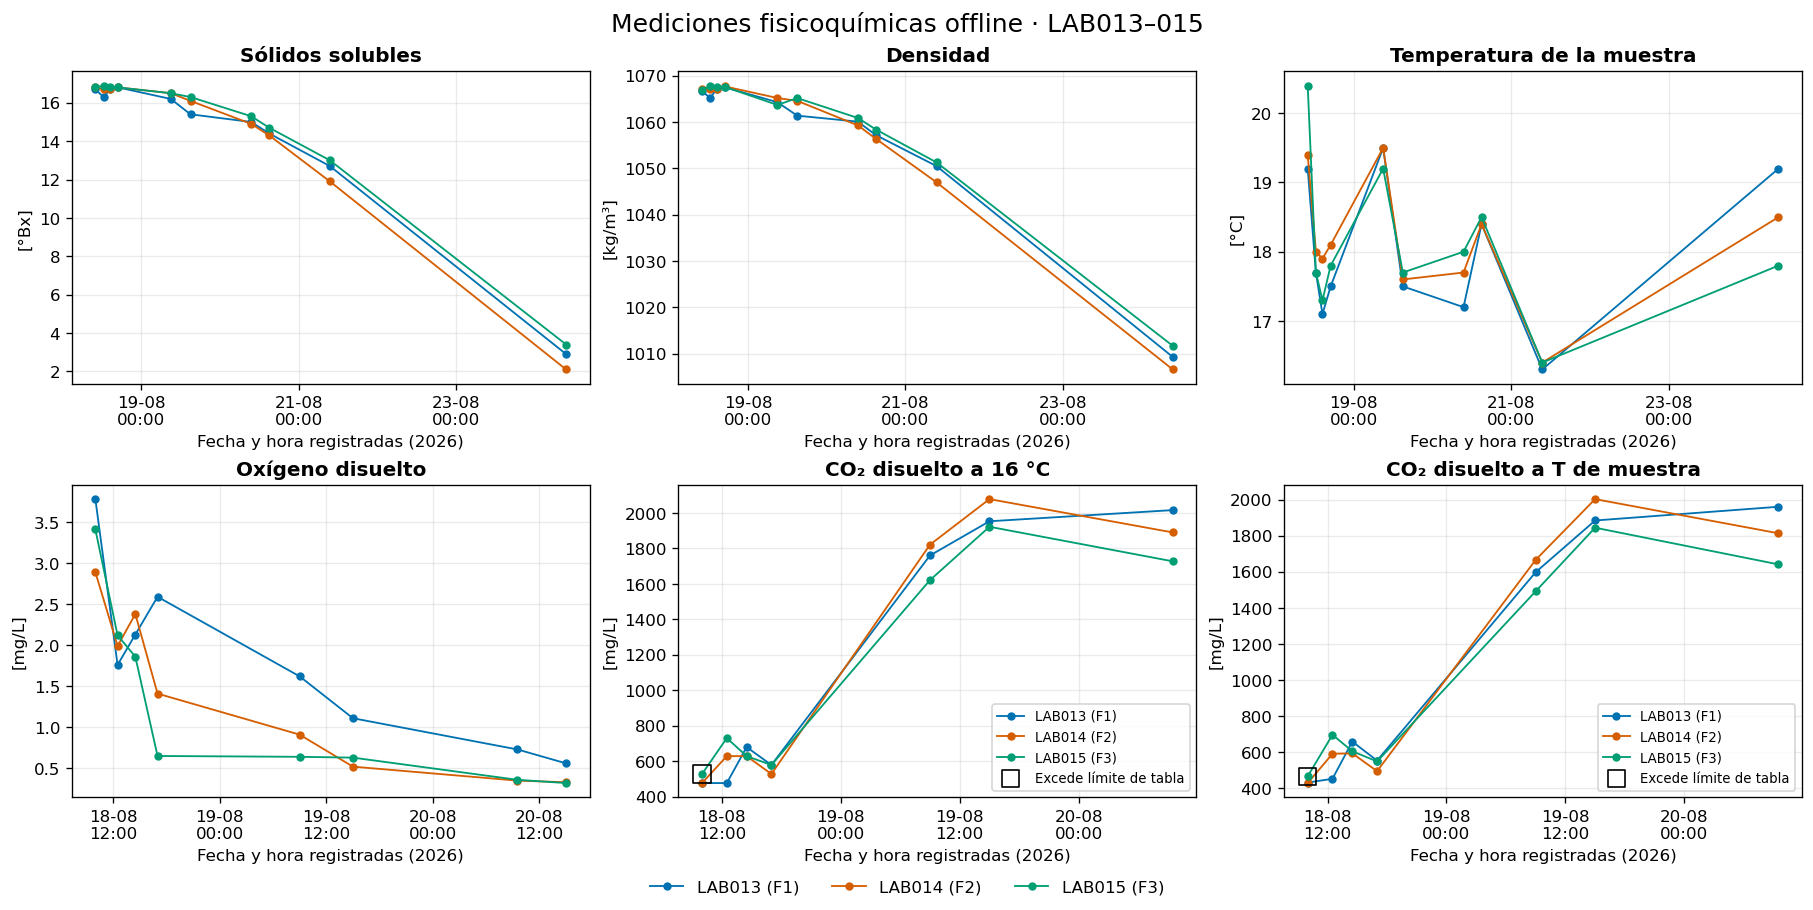

,sample_id,lab_id,timestamp,brix_degBx,rho_value,temperature_C,DO_value,CO2_dissolved_16C_mg_L,CO2_dissolved_actualT_mg_L,notes
0,LAB013-1,LAB013,2026-08-18 10:00:00,16.7,1066.7,19.2,3.78,476.0,431.2,NaN
3,LAB013-2,LAB013,2026-08-18 12:30:00,16.3,1065.2,17.7,1.76,476.0,452.2,NaN
6,LAB013-3,LAB013,2026-08-18 14:30:00,16.7,1067.2,17.1,2.13,679.0,658.2,NaN
9,LAB013-4,LAB013,2026-08-18 17:00:00,16.8,1067.5,17.5,2.59,578.0,553.0,NaN
12,LAB013-5,LAB013,2026-08-19 09:00:00,16.2,1064.3,19.5,1.62,1760.0,1597.5,NaN
15,LAB013-6,LAB013,2026-08-19 15:00:00,15.4,1061.4,17.5,1.11,1953.0,1884.5,NaN
18,LAB013-7,LAB013,2026-08-20 09:30:00,15.0,1060.1,17.2,0.73,2016.0,1960.6,NaN
21,LAB013-8,LAB013,2026-08-20 15:00:00,14.4,1057.2,18.4,0.56,NaN,NaN,NaN
24,LAB013-9,LAB013,2026-08-21 09:30:00,12.7,1050.5,16.3,NaN,NaN,NaN,NaN
27,LAB013-10,LAB013,2026-08-24 09:30:00,2.9,1009.3,19.2,NaN,NaN,NaN,NaN


In [29]:
OFFLINE = pd.read_excel(DATA / 'LAB013-LAB015-offline-measurements.xlsx', sheet_name='All_samples')
OFFLINE['timestamp'] = pd.to_datetime(OFFLINE['fecha_muestreo']).dt.normalize() + pd.to_timedelta(OFFLINE['hora_muestreo'].astype(str))
OFFLINE = OFFLINE.sort_values(['lab_id', 'timestamp'])
OFFLINE_VARIABLES = (
    ('brix_degBx', 'Sólidos solubles', '°Bx'),
    ('rho_value', 'Densidad', 'kg/m³'),
    ('temperature_C', 'Temperatura de la muestra', '°C'),
    ('DO_value', 'Oxígeno disuelto', 'mg/L'),
    ('CO2_dissolved_16C_mg_L', 'CO₂ disuelto a 16 °C', 'mg/L'),
    ('CO2_dissolved_actualT_mg_L', 'CO₂ disuelto a T de muestra', 'mg/L'),
)
fig_offline, axes_offline = plot_chemistry(OFFLINE, 'timestamp', OFFLINE_VARIABLES,
                                          'Mediciones fisicoquímicas offline · LAB013–015', (2, 3))
flagged = OFFLINE.loc[OFFLINE.notes.fillna('').str.contains('Excede', case=False)]
for ax, (column, _, _) in zip(axes_offline.flat, OFFLINE_VARIABLES):
    if column.startswith('CO2_dissolved'):
        ax.scatter(flagged.timestamp, flagged[column], s=105, marker='s', facecolors='none',
                   edgecolors='black', zorder=5, label='Excede límite de tabla')
        ax.legend(loc='lower right', fontsize=8)
plt.show()
display(OFFLINE[['sample_id', 'lab_id', 'timestamp', *[v[0] for v in OFFLINE_VARIABLES], 'notes']])